# 01_EDA_Preprocessing – Khám phá dữ liệu & Chiến lược tiền xử lý

**Đề tài:** Dự đoán giá nhà Ames Housing (hồi quy) · **Người phụ trách:** Lưu Ngọc Tuấn Anh

**Nguyên tắc chống rò rỉ dữ liệu:** mọi thống kê trong notebook này chỉ tính trên **tập train**.
Notebook chỉ *phân tích và đề xuất*; các bước học từ dữ liệu (impute, scale, encode) được thực hiện
**trong Pipeline** ở notebook 02, không fit trực tiếp ở đây.

| Mục | Nội dung |
|---|---|
| 1 | Đọc dữ liệu, chia train/test, kiểm tra cách đọc chuỗi `"None"` |
| 2 | Tổng quan dữ liệu |
| 3 | Biến mục tiêu `SalePrice` |
| 4 | Giá trị khuyết (missing values) |
| 5 | Ngoại lai |
| 6 | Tương quan |
| 7 | Biến phân loại |
| 8 | Tổng kết chiến lược tiền xử lý |

## 1. Đọc dữ liệu và chia train/test

Tập test (20%, `random_state=42`) đã được chia một lần và lưu Id ở `data/processed/test_ids.csv`.
Mọi phân tích và bước fit chỉ dùng **tập train**; tập test chỉ dùng để đánh giá cuối, tránh rò rỉ dữ liệu.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import FancyBboxPatch, Patch
from scipy import stats

# Thêm 03_SourceCode/ vào sys.path để import được thư mục src/
sys.path.append(str(Path.cwd().parent))

from src.data import ROOT, load_split, remove_outliers

# Cấu hình hiển thị chung
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Thư mục lưu hình cho báo cáo (01_Report/figures)
FIG_DIR = ROOT.parent / "01_Report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Lưu hình độ phân giải cao để chèn vào báo cáo / slide."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


X_train, X_test, y_train, y_test = load_split()
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1168, 79) | Test: (292, 79)


### 1.1. Kiểm tra cách đọc chuỗi `"None"`

`pandas.read_csv` mặc định coi một số chuỗi là giá trị khuyết, trong đó có **`"None"`**.
Nhưng trong Ames Housing, `"None"` là **một giá trị hợp lệ** của cột `MasVnrType`
(nghĩa là *nhà không ốp đá/gạch trang trí*, xem `data_description.txt`),
còn giá trị khuyết thật được ghi là `"NA"`.

→ Nếu đọc mặc định, các căn "không ốp" bị đếm nhầm thành *khuyết*, làm sai bảng missing.
Hàm `load_raw()` trong `src/data.py` đã đọc với `keep_default_na=False, na_values=["NA", ""]`
(chỉ coi `"NA"` và ô trống là khuyết). Kiểm tra lại:

In [2]:
# "None" phải là một giá trị, không bị đọc thành NaN
cot_none = [col for col in X_train.columns if X_train[col].astype(str).eq("None").any()]
print("Cột chứa chuỗi 'None':", cot_none)
print(X_train["MasVnrType"].value_counts(dropna=False))

Cột chứa chuỗi 'None': ['MasVnrType']
MasVnrType
None       677
BrkFace    366
Stone      106
BrkCmn      13
NaN          6
Name: count, dtype: int64


**Nhận xét:**
- Chỉ duy nhất cột `MasVnrType` chứa chuỗi `"None"`. Nếu đọc mặc định, tập train có **683** NaN ở cột này;
  đọc đúng thì **677** căn là `"None"` (không ốp), chỉ **6 căn khuyết thật**.
- 6 căn khuyết thật này **trùng đúng** 6 căn khuyết `MasVnrArea` (kiểm tra ở Mục 4.2).
- Cách đọc này nằm trong `src/data.py` nên notebook 02 và `predict.py` đọc dữ liệu nhất quán.

## 2. Tổng quan dữ liệu

In [3]:
print("Số dòng train:", X_train.shape[0], "| Số đặc trưng:", X_train.shape[1])
print("Số dòng trùng lặp:", X_train.duplicated().sum())

cot_so = X_train.select_dtypes(include="number").columns.tolist()
cot_phan_loai = X_train.select_dtypes(exclude="number").columns.tolist()
print(f"Cột số: {len(cot_so)} | Cột phân loại: {len(cot_phan_loai)}")
X_train.head()

Số dòng train: 1168 | Số đặc trưng: 79
Số dòng trùng lặp: 0
Cột số: 36 | Cột phân loại: 43


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal


In [4]:
# Thống kê mô tả các cột số
X_train[cot_so].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
MSSubClass,1168.0,56.8,42.5,20.0,20.0,50.0,70.0,190.0
LotFrontage,951.0,70.3,24.9,21.0,59.0,70.0,80.0,313.0
LotArea,1168.0,10689.6,10759.4,1300.0,7587.2,9600.0,11700.0,215245.0
OverallQual,1168.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
OverallCond,1168.0,5.6,1.1,1.0,5.0,5.0,6.0,9.0
YearBuilt,1168.0,1971.0,30.7,1872.0,1953.0,1972.0,2001.0,2010.0
YearRemodAdd,1168.0,1984.9,20.7,1950.0,1966.0,1994.0,2004.0,2010.0
MasVnrArea,1162.0,103.8,173.0,0.0,0.0,0.0,166.0,1378.0
BsmtFinSF1,1168.0,446.0,459.1,0.0,0.0,384.5,721.0,5644.0
BsmtFinSF2,1168.0,45.2,158.2,0.0,0.0,0.0,0.0,1127.0


In [5]:
# Số giá trị khác nhau (cardinality) của các cột phân loại
# và tỷ lệ của giá trị phổ biến nhất -> phát hiện cột gần như hằng số
card = pd.DataFrame({
    "so_gia_tri": X_train[cot_phan_loai].nunique(),
    "gia_tri_pho_bien": X_train[cot_phan_loai].mode().iloc[0],
    "ty_le_pho_bien_%": (
        X_train[cot_phan_loai]
        .apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)
        .round(1)
    ),
}).sort_values("ty_le_pho_bien_%", ascending=False)
card.head(10)

,so_gia_tri,gia_tri_pho_bien,ty_le_pho_bien_%
Utilities,2,AllPub,99.9
Street,2,Pave,99.7
Condition2,8,Norm,99.1
RoofMatl,7,CompShg,98.4
Heating,6,GasA,97.6
GarageCond,5,TA,96.1
GarageQual,5,TA,95.1
LandSlope,3,Gtl,94.9
CentralAir,2,Y,92.9
Functional,7,Typ,92.8


In [6]:
# Một số cột kiểu số nhưng thực chất là mã phân loại / thứ bậc
print("MSSubClass – số giá trị:", X_train["MSSubClass"].nunique(),
      "->", sorted(X_train["MSSubClass"].unique()))
print("OverallQual – thang:", sorted(X_train["OverallQual"].unique()))
print("MoSold – thang:", sorted(X_train["MoSold"].unique()))

MSSubClass – số giá trị: 15 -> [np.int64(20), np.int64(30), np.int64(40), np.int64(45), np.int64(50), np.int64(60), np.int64(70), np.int64(75), np.int64(80), np.int64(85), np.int64(90), np.int64(120), np.int64(160), np.int64(180), np.int64(190)]
OverallQual – thang: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
MoSold – thang: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


**Nhận xét:**
- Tập train có **1.168 căn × 79 đặc trưng**, không có dòng trùng lặp; gồm **36 cột số** và **43 cột phân loại**.
- **Cột gần như hằng số:** `Utilities` (1.167/1.168 căn là `AllPub`), `Street` (99,7% `Pave`),
  `Condition2` (99,1%), `RoofMatl` (98,4%), `Heating` (97,6%)…
  gần như không mang thông tin → ứng viên để loại hoặc để mô hình tự bỏ qua.
- **Cột số nhưng là mã phân loại:** `MSSubClass` (15 mã loại nhà, ví dụ 20 = nhà 1 tầng xây từ 1946)
  → cần mã hóa như biến phân loại, không coi là số liên tục.
  `MoSold` (tháng bán) cũng là biến chu kỳ, không có quan hệ tuyến tính "tháng 12 > tháng 1".
- **Cột thứ bậc:** `OverallQual`, `OverallCond` (thang 1–10) đã ở dạng số, giữ nguyên.
  Nhiều cột chất lượng dạng chữ (`Ex/Gd/TA/Fa/Po`) sẽ phân tích kỹ ở Mục 7.

## 3. Biến mục tiêu `SalePrice`

In [7]:
y_train.describe().round(0)

count      1168.0
mean     181442.0
std       77264.0
min       34900.0
25%      130000.0
50%      165000.0
75%      214925.0
max      745000.0
Name: SalePrice, dtype: float64

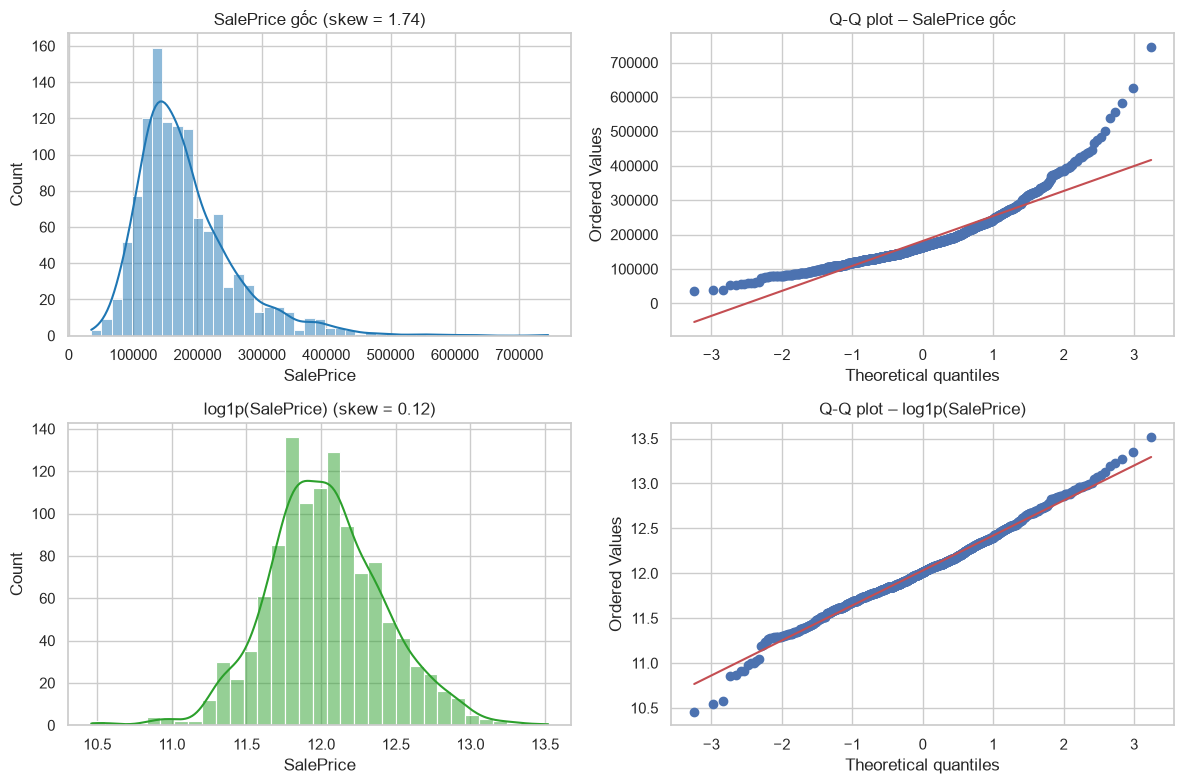

                  skewness  kurtosis
SalePrice            1.743     5.475
log1p(SalePrice)     0.125     0.700


In [8]:
y_log = np.log1p(y_train)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Hàng 1: giá gốc
sns.histplot(y_train, kde=True, ax=axes[0, 0], color="tab:blue")
axes[0, 0].set_title(f"SalePrice gốc (skew = {y_train.skew():.2f})")
stats.probplot(y_train, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Q-Q plot – SalePrice gốc")

# Hàng 2: sau log1p
sns.histplot(y_log, kde=True, ax=axes[1, 0], color="tab:green")
axes[1, 0].set_title(f"log1p(SalePrice) (skew = {y_log.skew():.2f})")
stats.probplot(y_log, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot – log1p(SalePrice)")

fig.tight_layout()
save_fig(fig, "eda_01_saleprice_phan_phoi")
plt.show()

print(pd.DataFrame({
    "skewness": [y_train.skew(), y_log.skew()],
    "kurtosis": [y_train.kurt(), y_log.kurt()],
}, index=["SalePrice", "log1p(SalePrice)"]).round(3))

**Nhận xét:**
- Giá nhà trên tập train dao động **34.900 – 745.000 USD**, trung vị **165.000 USD**, trung bình 181.442 USD
  (trung bình > trung vị → phân phối **lệch phải**: có một số căn rất đắt kéo đuôi phải dài).
- Độ lệch **skew = 1,74**, độ nhọn **kurtosis = 5,48**; Q-Q plot cong rõ ở hai đầu → không chuẩn.
- Sau biến đổi **`log1p`**: skew giảm còn **0,13**, kurtosis 0,70; Q-Q plot gần thẳng → gần phân phối chuẩn.

**Quyết định:** huấn luyện mô hình trên `log1p(SalePrice)`, khi dự đoán dùng `expm1` để đổi về USD. Lý do:
1. Mô hình tuyến tính (Ridge/Lasso) giả định phần dư gần chuẩn, phương sai đồng nhất – log giúp thỏa giả định này.
2. Sai số trên thang log tương ứng **sai số tương đối (%)**: sai 20.000 USD với căn 100.000 USD
   nghiêm trọng hơn nhiều so với căn 700.000 USD. RMSE trên log chính là **RMSLE** – chỉ số chính của bài toán.
3. Giảm ảnh hưởng của các căn giá rất cao lên hàm mất mát.

*Ghi chú kỹ thuật:* `log1p` là phép biến đổi cố định (không học tham số từ dữ liệu) nên không gây rò rỉ.
Trong Pipeline có thể dùng `TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1)`.

## 4. Giá trị khuyết (Missing values)

### 4.1. Tổng quan

In [9]:
so_khuyet = X_train.isna().sum()
bang_khuyet = (
    pd.DataFrame({
        "so_khuyet": so_khuyet,
        "ty_le_%": (so_khuyet / len(X_train) * 100).round(2),
        "kieu": X_train.dtypes.astype(str),
    })
    .query("so_khuyet > 0")
    .sort_values("so_khuyet", ascending=False)
)
print("Số cột có giá trị khuyết:", len(bang_khuyet))
bang_khuyet

Số cột có giá trị khuyết: 19


,so_khuyet,ty_le_%,kieu
PoolQC,1162,99.49,str
MiscFeature,1122,96.06,str
Alley,1094,93.66,str
Fence,935,80.05,str
FireplaceQu,547,46.83,str
LotFrontage,217,18.58,float64
GarageCond,64,5.48,str
GarageType,64,5.48,str
GarageYrBlt,64,5.48,float64
GarageFinish,64,5.48,str


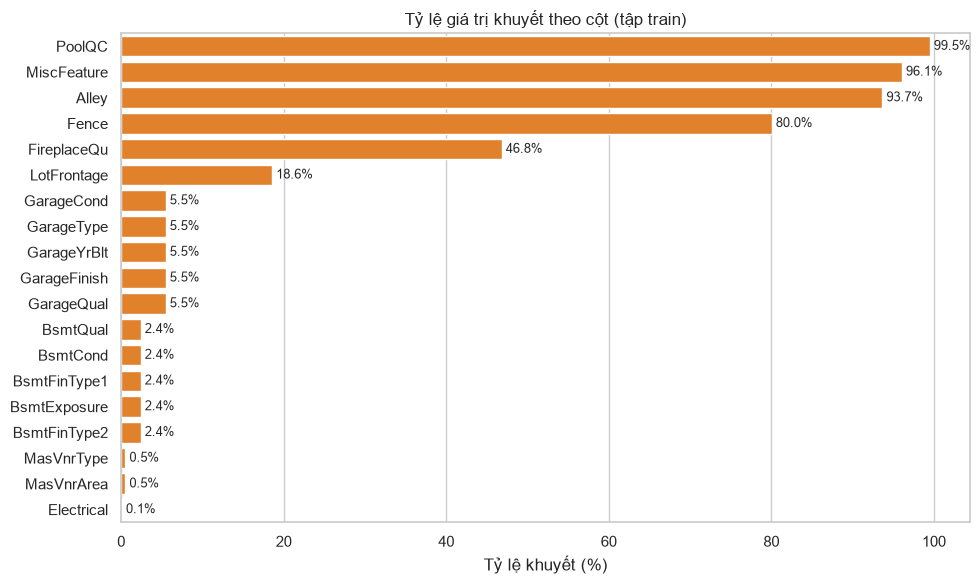

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x=bang_khuyet["ty_le_%"], y=bang_khuyet.index, ax=ax, color="tab:orange"
)
ax.set_xlabel("Tỷ lệ khuyết (%)")
ax.set_ylabel("")
ax.set_title("Tỷ lệ giá trị khuyết theo cột (tập train)")
for i, v in enumerate(bang_khuyet["ty_le_%"]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
fig.tight_layout()
save_fig(fig, "eda_02_ty_le_khuyet")
plt.show()

Theo `data_description.txt`, ở nhiều cột **`NA` không có nghĩa là "thiếu thông tin"** mà là
**"căn nhà không có hạng mục đó"** (ví dụ `PoolQC = NA` → *No Pool*). Vì vậy không thể xử lý
mọi NaN giống nhau. Ta kiểm chứng điều này bằng cách đối chiếu với cột số liên quan.

### 4.2. Kiểm chứng: NA có thực sự là "không có"?

In [11]:
def kiem_tra(ten, dk_khuyet, dk_khong_co):
    """So sánh tập dòng bị khuyết với tập dòng 'không có hạng mục'."""
    return {
        "nhom": ten,
        "so_dong_NA": int(dk_khuyet.sum()),
        "so_dong_khong_co": int(dk_khong_co.sum()),
        "so_dong_lech": int((dk_khuyet != dk_khong_co).sum()),
    }


cot_garage = ["GarageType", "GarageYrBlt", "GarageFinish", "GarageQual", "GarageCond"]
cot_bsmt = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
Xt = X_train

kiem_chung = pd.DataFrame([
    kiem_tra("Garage* (5 cột) ~ GarageArea = 0",
             Xt[cot_garage].isna().all(axis=1), Xt["GarageArea"] == 0),
    kiem_tra("Bsmt* (5 cột) ~ TotalBsmtSF = 0",
             Xt[cot_bsmt].isna().all(axis=1), Xt["TotalBsmtSF"] == 0),
    kiem_tra("FireplaceQu ~ Fireplaces = 0",
             Xt["FireplaceQu"].isna(), Xt["Fireplaces"] == 0),
    kiem_tra("PoolQC ~ PoolArea = 0",
             Xt["PoolQC"].isna(), Xt["PoolArea"] == 0),
    kiem_tra("MiscFeature ~ MiscVal = 0",
             Xt["MiscFeature"].isna(), Xt["MiscVal"] == 0),
    kiem_tra("MasVnrType ~ MasVnrArea khuyết",
             Xt["MasVnrType"].isna(), Xt["MasVnrArea"].isna()),
])
kiem_chung

,nhom,so_dong_NA,so_dong_khong_co,so_dong_lech
0,Garage* (5 cột) ~ GarageArea = 0,64,64,0
1,Bsmt* (5 cột) ~ TotalBsmtSF = 0,28,28,0
2,FireplaceQu ~ Fireplaces = 0,547,547,0
3,PoolQC ~ PoolArea = 0,1162,1162,0
4,MiscFeature ~ MiscVal = 0,1122,1124,2
5,MasVnrType ~ MasVnrArea khuyết,6,6,0


In [12]:
# Soi kỹ các trường hợp lệch
print("MiscFeature có giá trị nhưng MiscVal = 0:")
print(Xt.loc[Xt["MiscFeature"].notna() & (Xt["MiscVal"] == 0),
             ["MiscFeature", "MiscVal"]])

print("\nMasVnrType = 'None' nhưng MasVnrArea > 0:")
print(Xt.loc[(Xt["MasVnrType"] == "None") & (Xt["MasVnrArea"] > 0),
             ["MasVnrType", "MasVnrArea"]])

print("\nMasVnrType có loại ốp nhưng MasVnrArea = 0:")
print(Xt.loc[Xt["MasVnrType"].notna() & (Xt["MasVnrType"] != "None")
             & (Xt["MasVnrArea"] == 0), ["MasVnrType", "MasVnrArea"]])

MiscFeature có giá trị nhưng MiscVal = 0:
     MiscFeature  MiscVal
873         Othr        0
1200        Shed        0

MasVnrType = 'None' nhưng MasVnrArea > 0:
     MasVnrType  MasVnrArea
624        None       288.0
773        None         1.0
1230       None         1.0
1300       None       344.0
1334       None       312.0

MasVnrType có loại ốp nhưng MasVnrArea = 0:
     MasVnrType  MasVnrArea
688     BrkFace         0.0
1241      Stone         0.0


**Nhận xét:**
- **Garage, Bsmt, FireplaceQu, PoolQC:** tập dòng NA **trùng khớp 100%** với tập căn *không có*
  hạng mục tương ứng (diện tích / số lượng = 0). → NA ở đây là **thông tin "không có"**, không phải khuyết.
- **MiscFeature:** chỉ lệch 2 dòng (có ghi tiện ích nhưng `MiscVal = 0` – tiện ích không có giá trị quy đổi), hợp lý.
- **MasVnrType:** 6 dòng khuyết trùng với 6 dòng khuyết `MasVnrArea` → khuyết thật nhưng *cùng một hồ sơ*.
  Có một vài dòng mâu thuẫn nhẹ (`"None"` nhưng diện tích > 0 và ngược lại) – lỗi nhập liệu nhỏ, số lượng không đáng kể.

### 4.3. Missing có liên quan đến giá không?
Nếu việc "không có hạng mục" ảnh hưởng đến giá thì đó là **thông tin hữu ích** – không được xóa dòng/cột một cách tùy tiện.

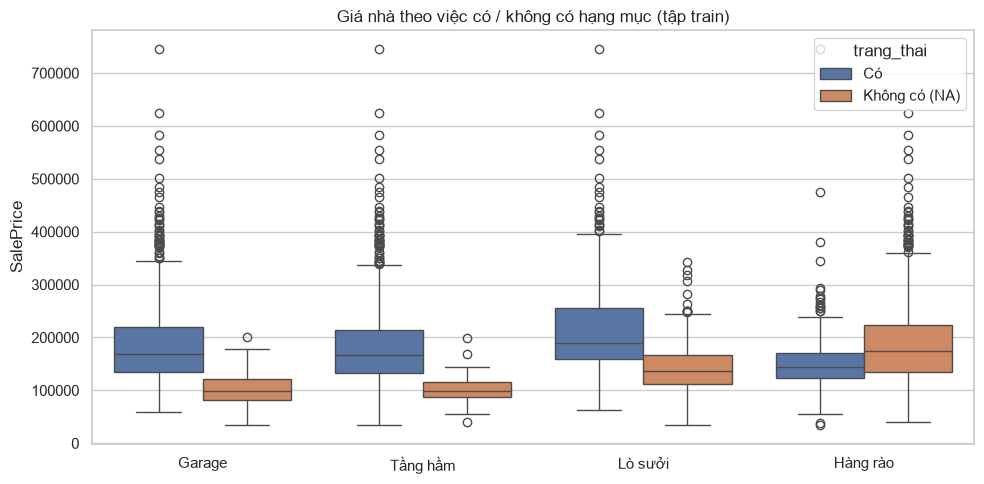

trang_thai,Có,Không có (NA)
hang_muc,,
Garage,169250.0,98950.0
Hàng rào,144000.0,174000.0
Lò sưởi,190000.0,136500.0
Tầng hầm,167000.0,99150.0


In [13]:
nhom_so_sanh = {
    "Garage": Xt["GarageType"].isna(),
    "Tầng hầm": Xt["BsmtQual"].isna(),
    "Lò sưởi": Xt["FireplaceQu"].isna(),
    "Hàng rào": Xt["Fence"].isna(),
}
du_lieu_ve = pd.concat([
    pd.DataFrame({
        "hang_muc": ten,
        "trang_thai": np.where(dk, "Không có (NA)", "Có"),
        "SalePrice": y_train.values,
    })
    for ten, dk in nhom_so_sanh.items()
])

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=du_lieu_ve, x="hang_muc", y="SalePrice", hue="trang_thai", ax=ax)
ax.set_title("Giá nhà theo việc có / không có hạng mục (tập train)")
ax.set_xlabel("")
fig.tight_layout()
save_fig(fig, "eda_03_khuyet_va_gia")
plt.show()

du_lieu_ve.groupby(["hang_muc", "trang_thai"])["SalePrice"].median().unstack()

**Nhận xét:** nhà **không có garage** có giá trung vị chỉ ≈ **99.000 USD**, so với ≈ **169.000 USD** của nhà có garage;
xu hướng tương tự với tầng hầm và lò sưởi. → Trạng thái "không có" **mang thông tin về giá**,
nên giữ lại dưới dạng một hạng mục riêng (`"None"`) thay vì xóa dòng.
Riêng hàng rào thì ngược lại: nhà *có* hàng rào có trung vị **thấp hơn** (≈ 144.000 so với 174.000 USD) –
có thể do hàng rào phổ biến ở các khu nhà cũ; đây là tương quan, không phải nhân quả.

### 4.4. Khuyết thật: `LotFrontage` (chiều dài mặt tiền tiếp giáp đường)

LotFrontage khuyết: 217 (18.6%)
Tương quan với LotArea: 0.427
Tương quan với sqrt(LotArea): 0.605


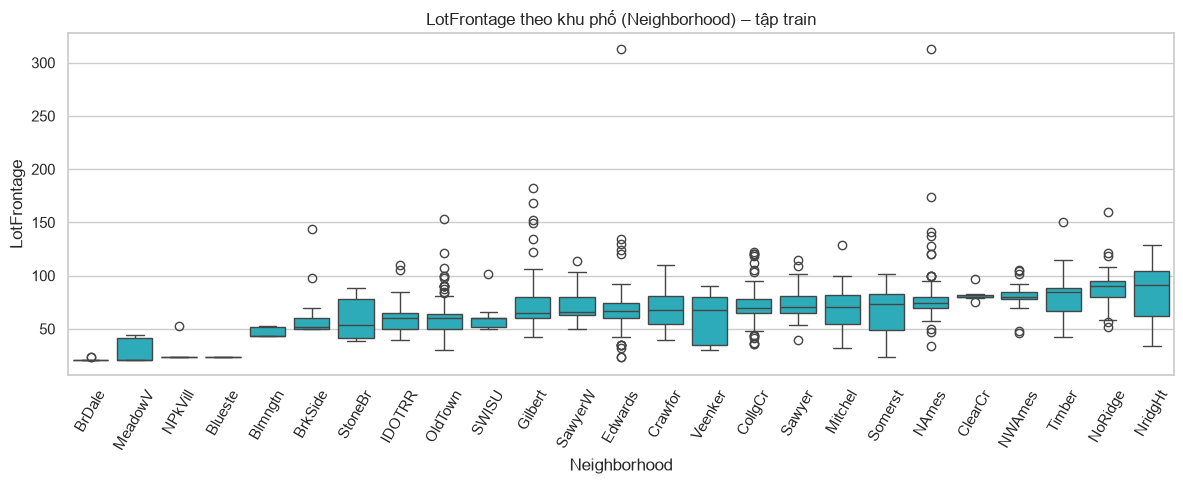

In [14]:
print("LotFrontage khuyết:", Xt["LotFrontage"].isna().sum(),
      f"({Xt['LotFrontage'].isna().mean() * 100:.1f}%)")
print("Tương quan với LotArea:", round(Xt["LotFrontage"].corr(Xt["LotArea"]), 3))
print("Tương quan với sqrt(LotArea):",
      round(Xt["LotFrontage"].corr(np.sqrt(Xt["LotArea"])), 3))

# Trung vị LotFrontage theo khu phố
thu_tu = Xt.groupby("Neighborhood")["LotFrontage"].median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=Xt, x="Neighborhood", y="LotFrontage", order=thu_tu, ax=ax,
            color="tab:cyan")
ax.tick_params(axis="x", rotation=60)
ax.set_title("LotFrontage theo khu phố (Neighborhood) – tập train")
fig.tight_layout()
save_fig(fig, "eda_04_lotfrontage_neighborhood")
plt.show()

**Nhận xét:** `LotFrontage` khuyết **18,6%** – đây là **khuyết thật** (mọi lô đất đều tiếp giáp đường).
- Trung vị theo khu phố dao động rất rộng (≈ 21 → 92 feet): các khu nhà liền kề / nhà phố
  (`BrDale`, `MeadowV`, `NPkVill`) mặt tiền hẹp chỉ 21–24 feet, khu nhà cao cấp (`NoRidge`, `NridgHt`)
  rộng ≈ 90 feet → điền một trung vị chung cho cả thành phố sẽ sai lệch lớn.
- Một số khu phố có rất ít dữ liệu (`Blueste` chỉ 1 giá trị, `NPkVill` 5 giá trị) → cần phương án dự phòng.
- Tương quan với $\sqrt{\text{LotArea}}$ (0,61) cao hơn với `LotArea` (0,43) – hợp lý vì mặt tiền là *chiều dài*, diện tích là *bình phương chiều dài*.

**Đề xuất:** điền bằng **trung vị theo `Neighborhood`** (tính trên fold train), dự phòng trung vị toàn cục nếu khu phố không có dữ liệu.
Đây là phép *học từ dữ liệu* nên **bắt buộc phải nằm trong Pipeline** (custom transformer trong `src/`),
không được `fillna` trước khi chia K-Fold.

### 4.5. Chiến lược xử lý giá trị khuyết

In [15]:
chien_luoc = pd.DataFrame([
    ("PoolQC, MiscFeature, Alley, Fence, FireplaceQu",
     "NA = không có", "Điền hằng số 'None'", "Pipeline (SimpleImputer constant)"),
    ("GarageType, GarageFinish, GarageQual, GarageCond",
     "NA = không có garage", "Điền 'None'", "Pipeline"),
    ("BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2",
     "NA = không có tầng hầm", "Điền 'None'", "Pipeline"),
    ("GarageYrBlt", "NA = không có garage (cột số)",
     "Điền YearBuilt của căn đó (không điền 0: năm 0 thành ngoại lai cực lớn) – chốt với Hinh",
     "Pipeline"),
    ("MasVnrType", "Khuyết thật (6 dòng)",
     "Điền 'None' (cùng hồ sơ thiếu MasVnrArea)", "Pipeline"),
    ("MasVnrArea", "Khuyết thật (6 dòng)", "Điền 0", "Pipeline"),
    ("LotFrontage", "Khuyết thật (18,6%)",
     "Trung vị theo Neighborhood", "Pipeline (custom transformer)"),
    ("Electrical", "Khuyết thật (1 dòng)", "Mode ('SBrkr')",
     "Pipeline (SimpleImputer most_frequent)"),
    ("Các cột khác", "Có thể khuyết ở dữ liệu mới",
     "Số: median · Phân loại: most_frequent", "Pipeline – để predict.py an toàn"),
], columns=["Cột", "Bản chất NA", "Cách xử lý đề xuất", "Thực hiện ở đâu"])
chien_luoc

,Cột,Bản chất NA,Cách xử lý đề xuất,Thực hiện ở đâu
0,"PoolQC, MiscFeature, Alley, Fence, FireplaceQu",NA = không có,Điền hằng số 'None',Pipeline (SimpleImputer constant)
1,"GarageType, GarageFinish, GarageQual, GarageCond",NA = không có garage,Điền 'None',Pipeline
2,"BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1...",NA = không có tầng hầm,Điền 'None',Pipeline
3,GarageYrBlt,NA = không có garage (cột số),Điền YearBuilt của căn đó (không điền 0: năm 0...,Pipeline
4,MasVnrType,Khuyết thật (6 dòng),Điền 'None' (cùng hồ sơ thiếu MasVnrArea),Pipeline
5,MasVnrArea,Khuyết thật (6 dòng),Điền 0,Pipeline
6,LotFrontage,"Khuyết thật (18,6%)",Trung vị theo Neighborhood,Pipeline (custom transformer)
7,Electrical,Khuyết thật (1 dòng),Mode ('SBrkr'),Pipeline (SimpleImputer most_frequent)
8,Các cột khác,Có thể khuyết ở dữ liệu mới,Số: median · Phân loại: most_frequent,Pipeline – để predict.py an toàn


**Kết luận Mục 4:**
1. Có **19 cột** khuyết trên tập train, nhưng phần lớn (**14 cột**) là NA mang nghĩa *"không có"*:
   12 cột đã đối chiếu khớp với cột diện tích/số lượng = 0 (Garage, Bsmt, FireplaceQu, PoolQC, MiscFeature),
   `Alley` và `Fence` theo định nghĩa trong `data_description.txt`. Chỉ **4 cột** khuyết thật
   (`LotFrontage`, `MasVnrType`, `MasVnrArea`, `Electrical`), cộng `GarageYrBlt` là trường hợp đặc biệt.
2. **Không xóa cột nào chỉ vì tỷ lệ khuyết cao** (kể cả `PoolQC` 99,5%): NA là thông tin.
   Việc có giữ các cột gần như hằng số hay không sẽ quyết định ở bước chọn đặc trưng.
3. **Không xóa dòng** – tập train chỉ có 1.168 dòng, xóa dòng sẽ mất dữ liệu.
4. Mọi phép điền đều đặt **trong Pipeline** để chống rò rỉ dữ liệu và để `predict.py` xử lý được dữ liệu mới có ô trống.

## 5. Ngoại lai (outliers)

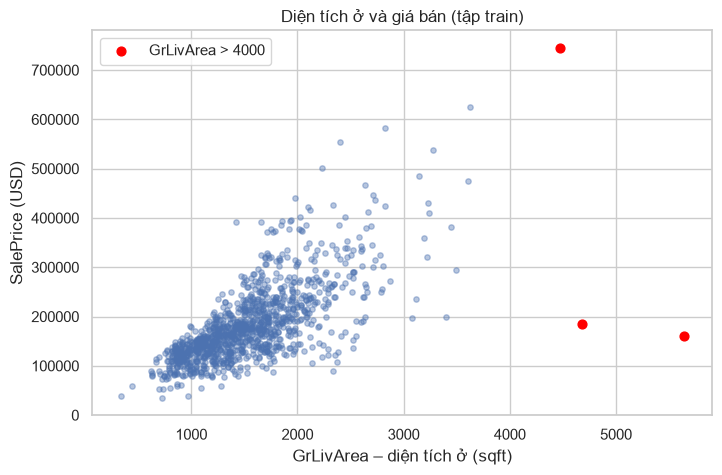

In [16]:
lon = X_train["GrLivArea"] > 4000

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train["GrLivArea"], y_train, alpha=0.4, s=15)
ax.scatter(X_train.loc[lon, "GrLivArea"], y_train[lon], color="red", s=40,
           label="GrLivArea > 4000")
ax.set_xlabel("GrLivArea – diện tích ở (sqft)")
ax.set_ylabel("SalePrice (USD)")
ax.set_title("Diện tích ở và giá bán (tập train)")
ax.legend()
save_fig(fig, "eda_05_ngoai_lai_grlivarea")
plt.show()

In [17]:
cot_xem = ["GrLivArea", "TotalBsmtSF", "OverallQual", "Neighborhood", "SaleCondition"]
X_train.loc[lon, cot_xem].assign(SalePrice=y_train[lon])

,GrLivArea,TotalBsmtSF,OverallQual,Neighborhood,SaleCondition,SalePrice
523,4676,3138,10,Edwards,Partial,184750
1182,4476,2396,10,NoRidge,Abnorml,745000
1298,5642,6110,10,Edwards,Partial,160000


**Nhận xét:**
- `GrLivArea` và giá có quan hệ gần tuyến tính, nhưng có 2 căn rất rộng (4.676 và 5.642 sqft, chất lượng 10/10)
  lại bán chỉ 160–185 nghìn USD, nằm hẳn dưới xu hướng chung.
- Cả 2 đều ở khu `Edwards` và có `SaleCondition = Partial` (nhà chưa hoàn thiện khi bán),
  nên giá không phản ánh giá trị thị trường thật.
- Căn còn lại (4.476 sqft, `NoRidge`, 745 nghìn USD, `SaleCondition = Abnorml`) có giá tương xứng diện tích.
  Tuy nhiên cả tập train chỉ có 3 căn trên 4.000 sqft, quá ít để mô hình học được phân khúc này.
- → Bỏ **tất cả** nhà có `GrLivArea > 4000` theo khuyến nghị của tác giả bộ dữ liệu (De Cock, 2011),
  bằng hàm `remove_outliers` trong `src/data.py`. Ngưỡng theo diện tích đơn giản, dễ giải thích và không dựa vào giá.

So sánh với cách loại ngoại lai máy móc bằng IQR trên `SalePrice`:

In [18]:
q1, q3 = y_train.quantile([0.25, 0.75])
nguong_tren = q3 + 1.5 * (q3 - q1)
print(f"Ngưỡng IQR trên: {nguong_tren:,.0f} USD -> sẽ loại {(y_train > nguong_tren).sum()} căn")

Ngưỡng IQR trên: 342,312 USD -> sẽ loại 48 căn


→ Dùng IQR trên giá sẽ bỏ 48 căn đắt nhưng hoàn toàn hợp lý, làm mô hình mất khả năng dự đoán phân khúc cao cấp.
Vì vậy chỉ loại theo diện tích như trên.

In [19]:
X_train_sach, y_train_sach = remove_outliers(X_train, y_train)
print("Trước:", X_train.shape, "| Sau:", X_train_sach.shape)

Trước: (1168, 79) | Sau: (1165, 79)


**Kết luận Mục 5:**
1. Loại **3 căn** có `GrLivArea > 4000` (2 căn bán khi chưa hoàn thiện, giá thấp bất thường) → train còn **1.165 căn**.
2. Chỉ loại trên **tập train**, trước khi đưa vào Pipeline. Tập test giữ nguyên để đánh giá khách quan.
   Bước này nằm ngoài Pipeline vì transformer của scikit-learn không được xóa dòng; ngưỡng cố định,
   không học từ tập test nên không gây rò rỉ.
3. Các giá trị lớn khác (ví dụ `LotArea` tới 215.245 sqft) là nhà thật, không loại;
   độ lệch của các biến diện tích sẽ xử lý bằng biến đổi log (Mục 6–8).

## 6. Tương quan với giá nhà

Từ mục này dùng tập train **đã loại ngoại lai** (`X_train_sach`, 1.165 căn) – đúng dữ liệu sẽ đưa vào huấn luyện –
và giá đã lấy `log1p` theo quyết định ở Mục 3.
`MSSubClass` là mã loại nhà nên không tính tương quan như biến số (phân tích ở Mục 7).

### 6.1. Biến số nào liên quan mạnh nhất tới giá?

In [20]:
Xs, ys_log = X_train_sach, np.log1p(y_train_sach)
cot_so_that = [c for c in cot_so if c != "MSSubClass"]

# Pearson đo quan hệ tuyến tính, Spearman đo quan hệ đơn điệu (dựa trên thứ hạng)
tuong_quan = pd.DataFrame({
    "pearson": Xs[cot_so_that].corrwith(ys_log),
    "spearman": Xs[cot_so_that].corrwith(ys_log, method="spearman"),
}).sort_values("pearson", ascending=False)
tuong_quan.round(3)

,pearson,spearman
OverallQual,0.812,0.802
GrLivArea,0.715,0.724
GarageCars,0.685,0.686
GarageArea,0.661,0.639
TotalBsmtSF,0.637,0.595
1stFlrSF,0.606,0.566
FullBath,0.582,0.625
YearBuilt,0.578,0.644
YearRemodAdd,0.564,0.564
GarageYrBlt,0.532,0.583


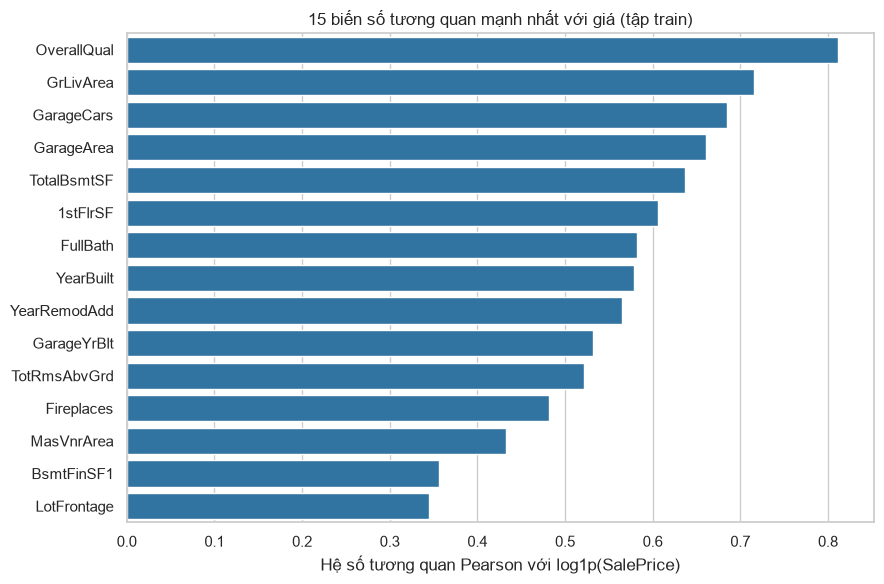

Biến gần như không tương quan tuyến tính (|r| < 0,1): 9 biến
['3SsnPorch', 'MoSold', 'PoolArea', 'BsmtFinSF2', 'YrSold', 'MiscVal', 'LowQualFinSF', 'BsmtHalfBath', 'OverallCond']


In [21]:
top15 = tuong_quan["pearson"].abs().sort_values(ascending=False).head(15).index

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=tuong_quan.loc[top15, "pearson"], y=top15, ax=ax, color="tab:blue")
ax.set_xlabel("Hệ số tương quan Pearson với log1p(SalePrice)")
ax.set_ylabel("")
ax.set_title("15 biến số tương quan mạnh nhất với giá (tập train)")
fig.tight_layout()
save_fig(fig, "eda_06_tuong_quan_top15")
plt.show()

yeu = tuong_quan.index[tuong_quan["pearson"].abs() < 0.1].tolist()
print(f"Biến gần như không tương quan tuyến tính (|r| < 0,1): {len(yeu)} biến")
print(yeu)

**Nhận xét:**
- Ba nhóm yếu tố quyết định giá: **chất lượng** (`OverallQual` r = 0,81 – mạnh nhất), **diện tích**
  (`GrLivArea` 0,72, `GarageCars` 0,69, `GarageArea` 0,66, `TotalBsmtSF` 0,64, `1stFlrSF` 0,61)
  và **tuổi nhà** (`YearBuilt` 0,58, `YearRemodAdd` 0,56).
- 9 biến gần như không tương quan tuyến tính (|r| < 0,1), đáng chú ý:
  `YrSold` (năm bán 2006–2010) và `MoSold` (tháng bán) gần như không ảnh hưởng giá;
  `OverallCond` (tình trạng nhà) ≈ 0 trái với trực giác – có thể vì nhà cũ được chấm tình trạng cao sau khi sửa.
- **Pearson và Spearman lệch nhau** ở `LotArea` (0,26 so với 0,46) và `OpenPorchSF` (0,31 so với 0,48):
  quan hệ đơn điệu nhưng không tuyến tính, do biến bị lệch mạnh → xử lý ở Mục 6.4.
- Lưu ý: tương quan chỉ xét **từng biến riêng lẻ** và **quan hệ tuyến tính**. Biến có r thấp vẫn có thể có ích
  khi kết hợp với biến khác (mô hình cây học được tương tác), nên **không loại biến chỉ dựa vào r**.

### 6.2. Đa cộng tuyến giữa các biến mạnh

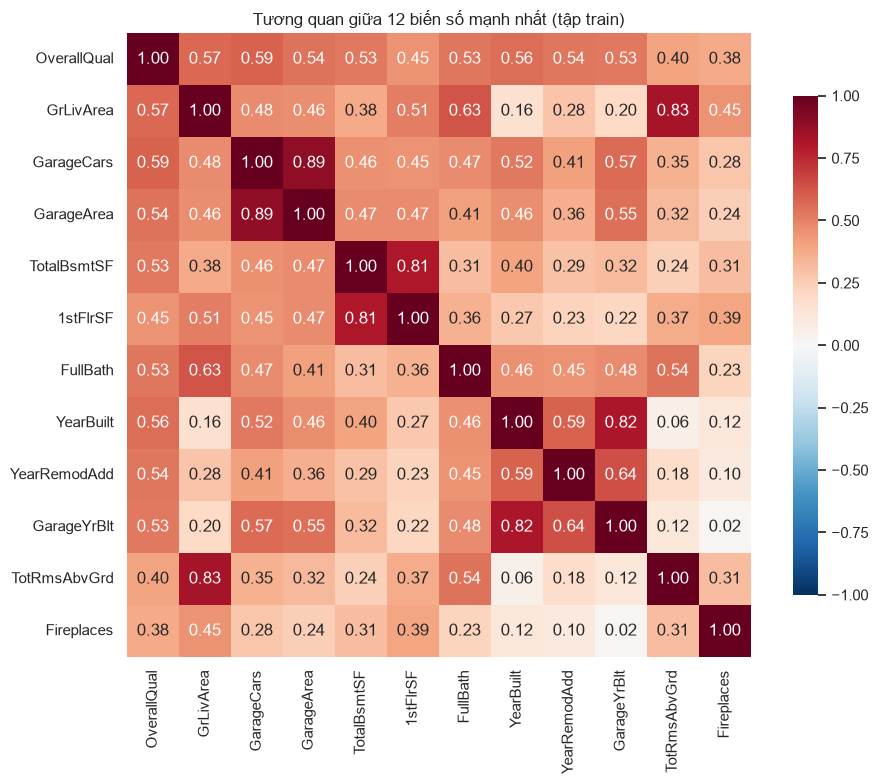

In [22]:
top12 = top15[:12]
ma_tran = Xs[top12].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(ma_tran, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Tương quan giữa 12 biến số mạnh nhất (tập train)")
fig.tight_layout()
save_fig(fig, "eda_07_heatmap_da_cong_tuyen")
plt.show()

In [23]:
# Lấy tam giác trên của ma trận để mỗi cặp chỉ xuất hiện một lần
tam_giac_tren = np.triu(np.ones(ma_tran.shape, dtype=bool), k=1)
cap_bien = ma_tran.where(tam_giac_tren).stack().reset_index()
cap_bien.columns = ["bien_1", "bien_2", "r"]
cap_bien[cap_bien["r"].abs() > 0.6].sort_values("r", ascending=False).round(3)

,bien_1,bien_2,r
27,GarageCars,GarageArea,0.889
22,GrLivArea,TotRmsAbvGrd,0.829
93,YearBuilt,GarageYrBlt,0.819
53,TotalBsmtSF,1stFlrSF,0.807
105,YearRemodAdd,GarageYrBlt,0.645
18,GrLivArea,FullBath,0.626


**Nhận xét:** có 4 cặp tương quan rất cao (r > 0,8) – thực chất là **cùng một thông tin đo hai lần**:

| Cặp biến | r | Giải thích |
|---|---|---|
| `GarageCars` – `GarageArea` | 0,89 | Gara chứa nhiều xe thì diện tích lớn |
| `GrLivArea` – `TotRmsAbvGrd` | 0,83 | Nhà rộng thì nhiều phòng |
| `YearBuilt` – `GarageYrBlt` | 0,82 | Gara thường xây cùng lúc với nhà |
| `TotalBsmtSF` – `1stFlrSF` | 0,81 | Tầng hầm nằm ngay dưới tầng 1 nên diện tích gần bằng nhau |

Hệ quả cho mô hình:
- **Hồi quy tuyến tính thường:** hệ số của hai biến trong cặp không ổn định (có thể đổi dấu), khó diễn giải
  → dùng **Ridge/Lasso** (có điều chuẩn) thay vì LinearRegression thuần.
- **Mô hình cây:** độ chính xác ít bị ảnh hưởng, nhưng **độ quan trọng đặc trưng bị chia đôi** giữa hai biến trong cặp
  – cần nhớ điều này khi đọc feature importance ở notebook 02.
- Gợi ý cho Feature Engineering (Hoàng Anh): gộp diện tích thành `TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF`;
  `GarageYrBlt` gần như trùng `YearBuilt` → củng cố cách điền `GarageYrBlt` bằng `YearBuilt` (Mục 4.5), hoặc bỏ hẳn cột này.

### 6.3. Giá theo chất lượng tổng thể `OverallQual`

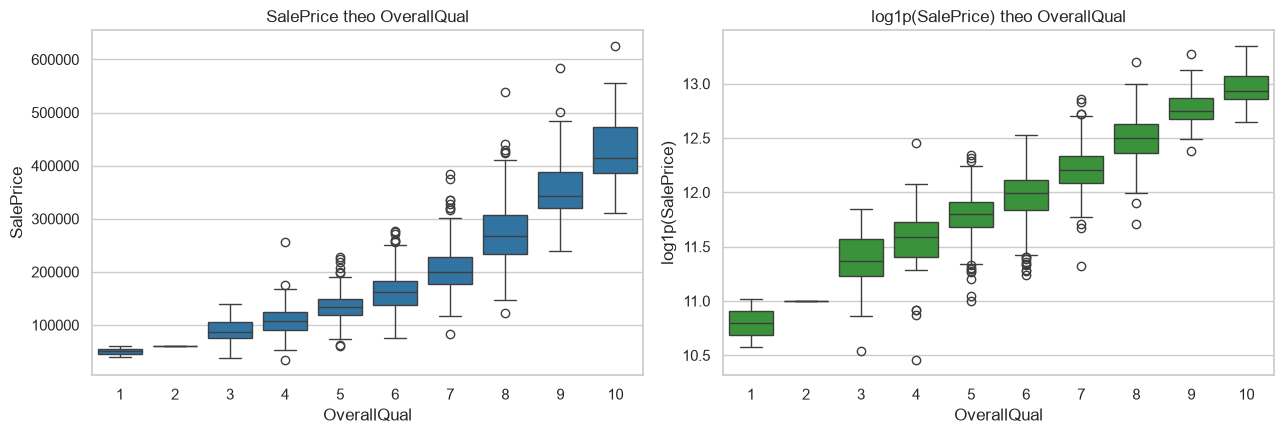

,count,median
OverallQual,,
1,2,50150.0
2,1,60000.0
3,16,86250.0
4,88,108250.0
5,308,133850.0
6,311,161750.0
7,258,200000.0
8,135,268000.0
9,36,343821.5


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(x=Xs["OverallQual"], y=y_train_sach, ax=axes[0], color="tab:blue")
axes[0].set_title("SalePrice theo OverallQual")
sns.boxplot(x=Xs["OverallQual"], y=ys_log, ax=axes[1], color="tab:green")
axes[1].set_title("log1p(SalePrice) theo OverallQual")
axes[1].set_ylabel("log1p(SalePrice)")
fig.tight_layout()
save_fig(fig, "eda_08_gia_theo_overallqual")
plt.show()

y_train_sach.groupby(Xs["OverallQual"]).agg(["count", "median"])

**Nhận xét:**
- Giá trung vị **tăng đều theo từng bậc** chất lượng: từ 86.250 USD (bậc 3) lên 414.431 USD (bậc 10).
- Trên thang giá gốc, khoảng cách giữa các bậc **ngày càng lớn** (bậc 5→6: +28 nghìn, bậc 8→9: +76 nghìn) – đường cong lồi.
  Trên thang log, các bậc tăng gần như **đều nhau** → quan hệ gần tuyến tính. Đây là thêm một lý do để huấn luyện trên `log1p(SalePrice)`:
  mô hình tuyến tính khớp tốt hơn khi quan hệ thẳng.
- Bậc 1–2 chỉ có 3 căn → dự đoán cho nhà chất lượng rất thấp sẽ kém tin cậy.
- `OverallQual` là thang thứ bậc 1–10, khoảng cách đều, quan hệ đơn điệu → **giữ dạng số**, không cần one-hot.

### 6.4. Độ lệch của các biến số
Ở Mục 3 ta đã lấy log cho biến mục tiêu. Các biến đầu vào bị lệch mạnh cũng làm mô hình tuyến tính và KNN kém đi
(vài giá trị cực lớn lấn át khoảng cách và hệ số).

In [25]:
do_lech = Xs[cot_so_that].skew().sort_values(ascending=False)
bang_lech = pd.DataFrame({
    "skew": do_lech,
    "skew_sau_log1p": np.log1p(Xs[do_lech.index]).skew(),
    "ty_le_bang_0_%": (Xs[do_lech.index] == 0).mean() * 100,
}).round(2)

lech_manh = bang_lech[bang_lech["skew"] > 0.75]
print("Số biến lệch mạnh (skew > 0,75):", len(lech_manh))
lech_manh

Số biến lệch mạnh (skew > 0,75): 18


,skew,skew_sau_log1p,ty_le_bang_0_%
MiscVal,22.03,5.00,96.22
PoolArea,17.62,17.01,99.66
LotArea,12.35,-0.06,0.00
3SsnPorch,9.82,7.50,98.28
LowQualFinSF,9.19,7.44,98.20
KitchenAbvGr,4.44,3.72,0.09
BsmtFinSF2,4.21,2.56,88.76
ScreenPorch,4.08,3.06,91.67
BsmtHalfBath,4.00,3.89,94.33
EnclosedPorch,3.16,2.17,86.27


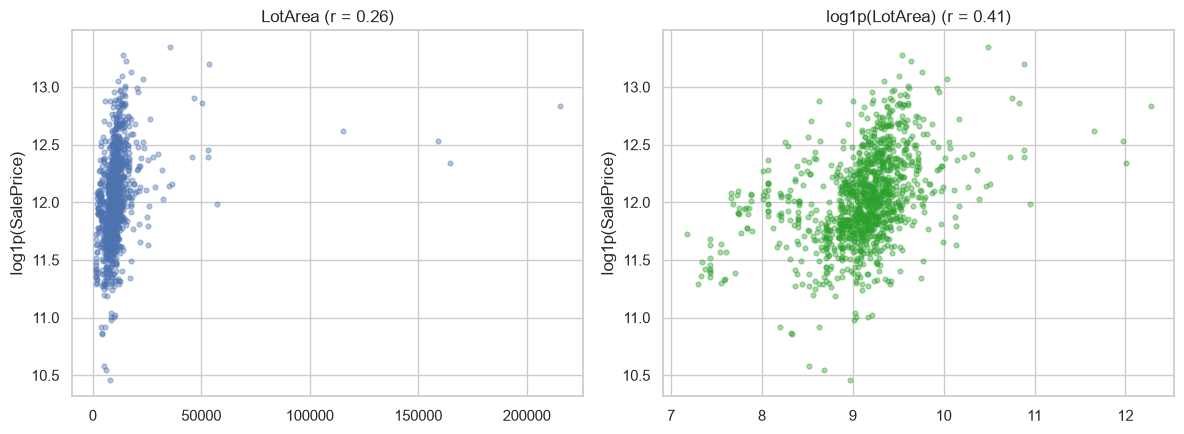

In [26]:
# Ví dụ LotArea: lệch mạnh nhất trong các biến diện tích "thật" (không có giá trị 0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(Xs["LotArea"], ys_log, alpha=0.4, s=12)
axes[0].set_title(f"LotArea (r = {Xs['LotArea'].corr(ys_log):.2f})")
axes[1].scatter(np.log1p(Xs["LotArea"]), ys_log, alpha=0.4, s=12, color="tab:green")
axes[1].set_title(f"log1p(LotArea) (r = {np.log1p(Xs['LotArea']).corr(ys_log):.2f})")
for ax in axes:
    ax.set_ylabel("log1p(SalePrice)")
fig.tight_layout()
save_fig(fig, "eda_09_log_lotarea")
plt.show()

**Nhận xét:** 18 biến lệch mạnh (skew > 0,75), chia làm 3 loại cần xử lý khác nhau:

| Loại | Biến | Tác dụng của `log1p` | Đề xuất |
|---|---|---|---|
| Diện tích/kích thước lệch, giá trị 0 không quá nhiều (≤ 58%) | `LotArea`, `GrLivArea`, `1stFlrSF`, `LotFrontage`, `OpenPorchSF`, `MasVnrArea`, `WoodDeckSF`, `2ndFlrSF` | Skew về gần 0 (`LotArea` 12,35 → −0,06) | Lấy `log1p` |
| Phần lớn bằng 0 (> 85% số căn) | `PoolArea`, `MiscVal`, `3SsnPorch`, `LowQualFinSF`, `BsmtHalfBath`, `ScreenPorch`, `BsmtFinSF2`, `EnclosedPorch` | Gần như vô tác dụng (`PoolArea` 17,62 → 17,01) | Giữ nguyên hoặc đổi thành cờ có/không (`HasPool`, `HasPorch`…) |
| Đếm rời rạc / lệch ngược sau log | `KitchenAbvGr`, `BsmtUnfSF` | Không cải thiện, `BsmtUnfSF` còn lệch ngược (0,91 → −2,19) | Không lấy log |

- Với `LotArea`, sau khi lấy log tương quan với giá tăng từ **0,26 lên 0,41**, đám điểm co lại thành dải thẳng.
- `log1p` là phép biến đổi **cố định** (không học tham số) nên có thể đặt trong Pipeline bằng
  `FunctionTransformer(np.log1p)` mà không gây rò rỉ. Nếu dùng `PowerTransformer` (Yeo-Johnson, có học tham số)
  thì bắt buộc phải nằm trong Pipeline để chỉ fit trên fold train.
- Mô hình cây không cần các biến đổi này (cây chỉ quan tâm thứ tự giá trị), chủ yếu giúp Ridge/Lasso và KNN.

## 7. Biến phân loại

### 7.1. Biến phân loại nào ảnh hưởng mạnh tới giá?
Với biến phân loại không tính được hệ số tương quan Pearson. Dùng **tỷ số tương quan η² (eta bình phương)**:
tỷ lệ phương sai của `log1p(SalePrice)` được giải thích khi chia các căn theo nhóm của biến đó.
η² = 0 nghĩa là các nhóm có giá trung bình như nhau; η² = 1 nghĩa là biết nhóm là biết chính xác giá (tương tự R²).

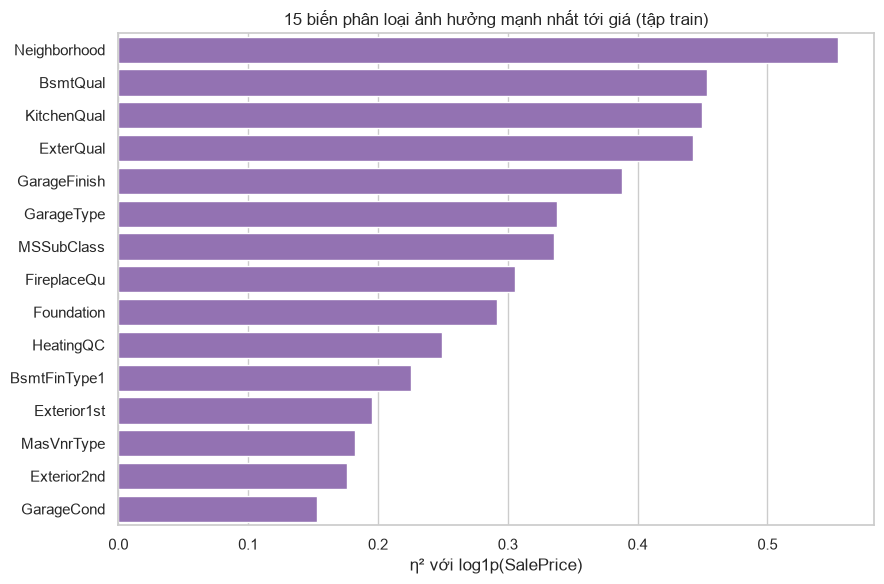

6 biến yếu nhất: {'RoofMatl': 0.01, 'MiscFeature': 0.008, 'LandSlope': 0.003, 'PoolQC': 0.003, 'Utilities': 0.0, 'Street': 0.0}


In [27]:
cot_pl = cot_phan_loai + ["MSSubClass"]


def eta_binh_phuong(cot):
    """η² = phương sai giữa các nhóm / phương sai toàn phần của log1p(SalePrice)."""
    nhom = Xs[cot].fillna("None").astype(str)
    tb = ys_log.mean()
    giua_nhom = ys_log.groupby(nhom).agg(lambda v: len(v) * (v.mean() - tb) ** 2).sum()
    return giua_nhom / ((ys_log - tb) ** 2).sum()


eta = pd.Series({c: eta_binh_phuong(c) for c in cot_pl}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=eta.head(15), y=eta.head(15).index, ax=ax, color="tab:purple")
ax.set_xlabel("η² với log1p(SalePrice)")
ax.set_ylabel("")
ax.set_title("15 biến phân loại ảnh hưởng mạnh nhất tới giá (tập train)")
fig.tight_layout()
save_fig(fig, "eda_10_eta_bien_phan_loai")
plt.show()

print("6 biến yếu nhất:", eta.tail(6).round(3).to_dict())

**Nhận xét:**
- `Neighborhood` (khu phố) mạnh nhất: η² = 0,55 – riêng vị trí đã giải thích hơn một nửa biến động của log giá.
- Tiếp theo là nhóm **thang chất lượng**: `BsmtQual` 0,45, `KitchenQual` 0,45, `ExterQual` 0,44,
  rồi đến gara (`GarageFinish` 0,39, `GarageType` 0,34) và loại nhà `MSSubClass` 0,34.
- Yếu nhất: `Utilities`, `Street` (η² ≈ 0), `PoolQC`, `LandSlope`, `MiscFeature`, `RoofMatl` (≤ 0,01) –
  khớp với nhóm cột gần như hằng số đã thấy ở Mục 2.
- Lưu ý: η² bị **thổi phồng** với biến có nhiều nhóm nhỏ (mỗi nhóm vài căn thì trung bình nhóm "khớp" dữ liệu quá mức),
  nên dùng để xếp hạng sơ bộ, không phải con số tuyệt đối.

### 7.2. Giá theo khu phố `Neighborhood`

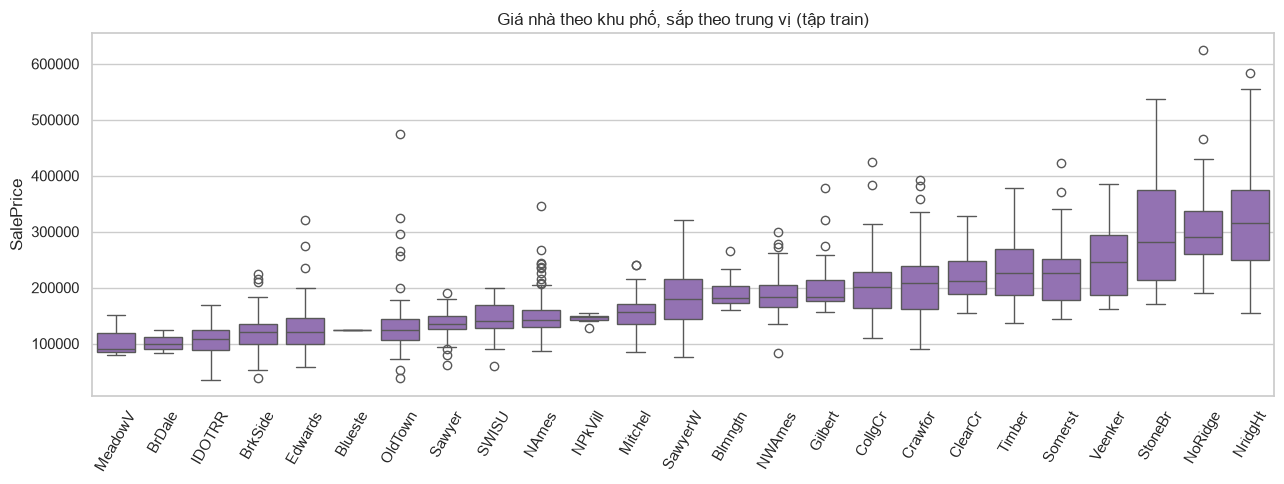

Khu rẻ nhất : MeadowV 89,500 USD
Khu đắt nhất: NridgHt 314,813 USD
Khu ít mẫu nhất: {'BrDale': 13, 'MeadowV': 10, 'Veenker': 9, 'NPkVill': 7, 'Blueste': 1}


In [28]:
thu_tu_khu = y_train_sach.groupby(Xs["Neighborhood"]).median().sort_values().index

fig, ax = plt.subplots(figsize=(13, 5))
sns.boxplot(x=Xs["Neighborhood"], y=y_train_sach, order=thu_tu_khu, ax=ax, color="tab:purple")
ax.tick_params(axis="x", rotation=60)
ax.set_xlabel("")
ax.set_title("Giá nhà theo khu phố, sắp theo trung vị (tập train)")
fig.tight_layout()
save_fig(fig, "eda_11_gia_theo_neighborhood")
plt.show()

trung_vi_khu = y_train_sach.groupby(Xs["Neighborhood"]).median()
print("Khu rẻ nhất :", trung_vi_khu.idxmin(), f"{trung_vi_khu.min():,.0f} USD")
print("Khu đắt nhất:", trung_vi_khu.idxmax(), f"{trung_vi_khu.max():,.0f} USD")
print("Khu ít mẫu nhất:", Xs["Neighborhood"].value_counts().tail(5).to_dict())

**Nhận xét:**
- Giá trung vị chênh **3,5 lần** giữa khu rẻ nhất (`MeadowV` 89.500 USD) và khu đắt nhất (`NridgHt` 314.813 USD).
  Các khu đắt (`NridgHt`, `NoRidge`, `StoneBr`) cũng là nơi có nhà chất lượng cao, mới xây.
- 25 khu không có thứ tự tự nhiên → **one-hot** (không dùng ordinal, vì gán số 1..25 sẽ tạo thứ tự giả).
- Một số khu rất ít mẫu: `Blueste` chỉ 1 căn, `NPkVill` 7, `Veenker` 9 → khi chia K-Fold có fold không chứa khu này,
  cần `OneHotEncoder(handle_unknown="ignore")` để không lỗi khi gặp khu chưa thấy.
- Không dùng *target encoding* (thay khu bằng giá trung bình của khu) ở bước này: dễ rò rỉ nhãn nếu không tính
  trong từng fold, và one-hot với 25 cột vẫn chấp nhận được.

### 7.3. Các cột thang chất lượng `Po < Fa < TA < Gd < Ex`
Theo `data_description.txt`, nhiều cột dùng chung thang 5 bậc: Po (kém), Fa (khá kém), TA (trung bình), Gd (tốt), Ex (xuất sắc).
Nếu giá tăng theo bậc thì nên mã hóa **thứ bậc** (ordinal) để giữ thông tin thứ tự.

In [29]:
thang = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
diem = {muc: i for i, muc in enumerate(thang)}  # None = 0, Po = 1, ..., Ex = 5

cot_chat_luong = [c for c in cot_phan_loai if set(Xs[c].dropna().unique()) <= set(thang[1:])]
print("Các cột dùng thang chất lượng:", cot_chat_luong)

gia_theo_bac = pd.DataFrame({
    c: y_train_sach.groupby(Xs[c].fillna("None")).median().reindex(thang)
    for c in cot_chat_luong
}).T
gia_theo_bac["spearman"] = [
    Xs[c].fillna("None").map(diem).corr(ys_log, method="spearman") for c in cot_chat_luong
]
gia_theo_bac.style.format("{:,.0f}", subset=thang, na_rep="–").format("{:.2f}", subset=["spearman"])

Các cột dùng thang chất lượng: ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']


,None,Po,Fa,TA,Gd,Ex,spearman
ExterQual,–,–,"85,000","140,000","220,000","366,398",0.67
ExterCond,–,"76,500","116,750","170,000","146,500","161,000",-0.01
BsmtQual,"99,150",–,"112,000","136,900","193,000","318,000",0.67
BsmtCond,"99,150","61,000","118,500","167,370","191,000",–,0.27
HeatingQC,–,"87,000","124,750","135,960","151,400","198,700",0.50
KitchenQual,–,–,"111,750","139,000","202,150","319,950",0.67
FireplaceQu,"136,500","136,500","158,000","187,500","206,900","310,000",0.53
GarageQual,"98,950","116,750","118,375","171,000","233,230","127,500",0.35
GarageCond,"98,950","121,000","114,504","171,250","148,000","124,000",0.33
PoolQC,"164,990",–,"215,500",–,"274,970","235,000",0.06


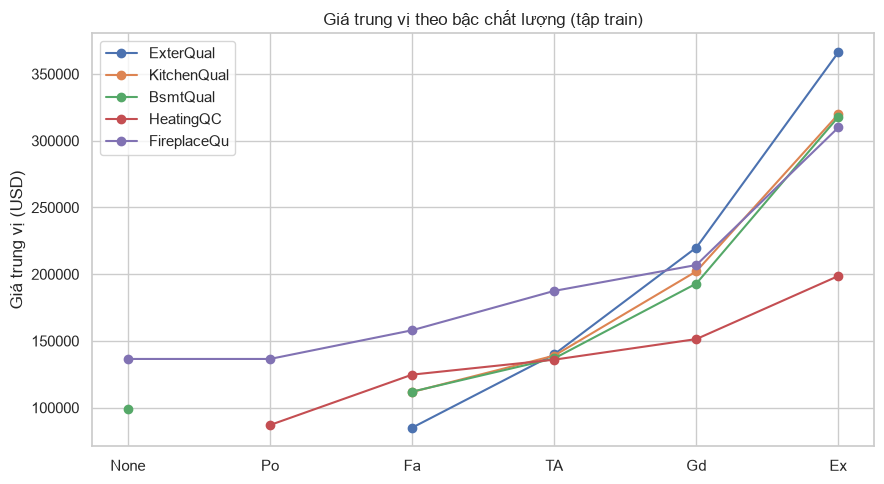

In [30]:
fig, ax = plt.subplots(figsize=(9, 5))
for c in ["ExterQual", "KitchenQual", "BsmtQual", "HeatingQC", "FireplaceQu"]:
    ax.plot(thang, gia_theo_bac.loc[c, thang], marker="o", label=c)
ax.set_ylabel("Giá trung vị (USD)")
ax.set_title("Giá trung vị theo bậc chất lượng (tập train)")
ax.legend()
fig.tight_layout()
save_fig(fig, "eda_12_gia_theo_bac_chat_luong")
plt.show()

In [31]:
# Hai cột có thứ tự nhưng không dùng thang Po–Ex
for c, thu_tu in {
    "BsmtExposure": ["None", "No", "Mn", "Av", "Gd"],
    "GarageFinish": ["None", "Unf", "RFn", "Fin"],
}.items():
    print(c, y_train_sach.groupby(Xs[c].fillna("None")).median().reindex(thu_tu).to_dict())

BsmtExposure {'None': 99150.0, 'No': 156000.0, 'Mn': 185000.0, 'Av': 187750.0, 'Gd': 215000.0}
GarageFinish {'None': 98950.0, 'Unf': 135000.0, 'RFn': 190000.0, 'Fin': 215000.0}


**Nhận xét:**
- 5 cột chất lượng **tăng đều theo bậc**: `ExterQual`, `KitchenQual`, `BsmtQual`, `HeatingQC`, `FireplaceQu`
  (ví dụ `KitchenQual`: Fa 111.750 → TA 139.000 → Gd 202.150 → Ex 319.950 USD; Spearman 0,50–0,67)
  → mã hóa **ordinal** `None = 0, Po = 1, …, Ex = 5`: 1 cột thay vì 5–6 cột one-hot, lại giữ được thứ tự.
- Các cột "tình trạng" liên quan yếu hơn nhiều (Spearman −0,01 đến 0,35):
  `ExterCond`, `GarageQual`, `GarageCond` **không tăng đều** ở bậc cao (ví dụ `ExterCond`: Gd 146.500 < TA 170.000;
  `GarageQual`: Ex 127.500 < TA 171.000), nhưng các bậc này chỉ có vài căn (`GarageQual = Ex` có 3 căn) nên trung vị không đáng tin.
  `BsmtCond` có tăng theo bậc nhưng gần 90% số căn cùng bậc TA nên ít thông tin.
  Vẫn có thể mã hóa ordinal cho gọn, mô hình sẽ tự gán trọng số thấp.
- `PoolQC` chỉ có 4 căn có hồ bơi → không đủ dữ liệu, đề xuất bỏ hoặc thay bằng cờ `HasPool` (như Mục 4).
- Hai cột thứ tự khác cũng tăng theo bậc → ordinal:
  `GarageFinish` (None 98.950 < Unf 135.000 < RFn 190.000 < Fin 215.000) và
  `BsmtExposure` (None 99.150 < No 156.000 < Mn 185.000 ≈ Av 187.750 < Gd 215.000).

### 7.4. Mức hiếm và số cột sau one-hot

In [32]:
so_muc = Xs[cot_pl].nunique()
muc_hiem = pd.Series({
    c: int((Xs[c].value_counts(normalize=True) < 0.01).sum()) for c in cot_pl
})

print("Số cột phân loại:", len(cot_pl))
print("Tổng số mức (chưa kể 'None' của cột bị khuyết):", so_muc.sum())
print(f"Số mức hiếm (< 1% số căn, tức dưới {int(0.01 * len(Xs)) + 1} căn):",
      muc_hiem.sum(), "mức, nằm ở", (muc_hiem > 0).sum(), "cột")
muc_hiem[muc_hiem > 0].sort_values(ascending=False).head(10)

Số cột phân loại: 44
Tổng số mức (chưa kể 'None' của cột bị khuyết): 264
Số mức hiếm (< 1% số căn, tức dưới 12 căn): 77 mức, nằm ở 29 cột


Condition2      7
SaleType        6
Exterior2nd     6
Exterior1st     5
RoofMatl        5
Condition1      4
Heating         4
Neighborhood    4
RoofStyle       4
Functional      3
dtype: int64

**Nhận xét:**
- Nếu one-hot toàn bộ 44 cột phân loại sẽ tạo ra khoảng **264 cột** (cộng thêm mức `"None"` ở 16 cột bị khuyết),
  trong khi chỉ có 1.165 căn → số đặc trưng lớn so với số mẫu, củng cố việc dùng **điều chuẩn (Ridge/Lasso)**.
  Mã hóa ordinal cho các cột chất lượng (Mục 7.3) giúp giảm bớt số cột.
- Có **77 mức hiếm** (mỗi mức dưới 12 căn) nằm ở 29 cột, nhiều nhất ở `Condition2` (7), `SaleType` (6), `Exterior2nd` (6), `Exterior1st` (5), `RoofMatl` (5).
  Mức hiếm gây 2 vấn đề:
  1. Khi chia 5-Fold, có fold huấn luyện không chứa mức đó → fold kiểm tra gặp mức lạ. Dữ liệu mới ở `predict.py` cũng vậy.
     → `OneHotEncoder(handle_unknown="ignore")`.
  2. Cột one-hot chỉ có vài số 1 dễ gây quá khớp → có thể gộp mức hiếm bằng tham số `min_frequency`
     của `OneHotEncoder` (ví dụ `min_frequency=10`); tham số này học từ dữ liệu nên chỉ đặt trong Pipeline.

**Kết luận Mục 7 – đề xuất mã hóa biến phân loại:**

| Nhóm | Cột | Cách mã hóa |
|---|---|---|
| Thang chất lượng | `ExterQual`, `KitchenQual`, `BsmtQual`, `HeatingQC`, `FireplaceQu`, `ExterCond`, `BsmtCond`, `GarageQual`, `GarageCond` | Ordinal `None = 0 … Ex = 5` |
| Thứ tự khác | `GarageFinish`, `BsmtExposure` | Ordinal theo thứ tự ở Mục 7.3 |
| Gần như hằng số / quá ít dữ liệu | `Utilities`, `Street`, `PoolQC` | Đề xuất bỏ (hoặc cờ `HasPool`) |
| Danh nghĩa (còn lại, gồm `Neighborhood`, `MSSubClass`) | ~30 cột | One-hot, `handle_unknown="ignore"`, cân nhắc `min_frequency` |

## 8. Tổng kết chiến lược tiền xử lý

Mục này gộp các kết luận ở Mục 3–7 thành một chiến lược thống nhất cho Pipeline ở notebook 02.
Trước khi chốt, kiểm tra thêm hai điểm còn bỏ ngỏ: bảng xử lý khuyết ở Mục 4.5 đã phủ hết các cột chưa,
và hai cột `BsmtFinType1/2` (chưa xét ở Mục 7.3) có nên mã hóa thứ bậc không.

### 8.1. Sau khi điền "không có", còn những cột nào khuyết?

In [33]:
# 14 cột phân loại có NA nghĩa là "không có" (Mục 4.2) -> điền "None" theo quy tắc cố định
cot_na_khong_co = [
    "Alley", "Fence", "PoolQC", "MiscFeature", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
]
thu = Xs.copy()  # bản sao để thử, không sửa dữ liệu dùng ở các mục trước
thu[cot_na_khong_co] = thu[cot_na_khong_co].fillna("None")

con_khuyet = thu.isna().sum()
con_khuyet[con_khuyet > 0].sort_values(ascending=False)

LotFrontage    217
GarageYrBlt     64
MasVnrType       6
MasVnrArea       6
Electrical       1
dtype: int64

**Nhận xét:**
- Sau khi điền `"None"` cho 14 cột, chỉ còn **5 cột** khuyết và cột nào cũng đã có cách xử lý trong bảng Mục 4.5:
  `LotFrontage` (217 căn) → trung vị theo `Neighborhood`; `GarageYrBlt` (64) → `YearBuilt` của căn đó;
  `MasVnrType`/`MasVnrArea` (6) → `"None"`/0; `Electrical` (1) → mode. → Chiến lược **không bỏ sót cột nào**.
- Trên tập train, NA ở các cột `Bsmt*` luôn đi cùng "không có tầng hầm" (Mục 4.2). Tuy nhiên dữ liệu mới
  (fold kiểm tra, `predict.py`) vẫn có thể có nhà **có** tầng hầm mà thiếu `BsmtExposure`.
  → Pipeline nên dự phòng: chỉ điền `"None"` khi căn nhà không có tầng hầm, còn lại điền mode học từ fold train.

### 8.2. `BsmtFinType1/2` có nên mã hóa thứ bậc?
Theo `data_description.txt`, kiểu hoàn thiện tầng hầm có thứ tự `Unf < LwQ < Rec < BLQ < ALQ < GLQ`
(chưa hoàn thiện → chất lượng sinh hoạt tốt). Kiểm tra giống như với thang chất lượng ở Mục 7.3.

In [34]:
thu_tu_fin = ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"]
diem_fin = {muc: i for i, muc in enumerate(thu_tu_fin)}

bang_fin = {}
for c in ["BsmtFinType1", "BsmtFinType2"]:
    nhom = Xs[c].fillna("None")
    print(c, "| Spearman:", round(nhom.map(diem_fin).corr(ys_log, method="spearman"), 2))
    bang_fin[c] = y_train_sach.groupby(nhom).agg(["count", "median"]).reindex(thu_tu_fin)

pd.concat(bang_fin, axis=1)  # số căn và giá trung vị (USD) theo từng kiểu hoàn thiện

BsmtFinType1 | Spearman: 0.34
BsmtFinType2 | Spearman: 0.06


BsmtFinType1           BsmtFinType2          
            count    median        count    median
None           28   99150.0           28   99150.0
Unf           345  167500.0         1006  167950.0
LwQ            62  138450.0           36  154000.0
Rec           104  144000.0           46  148750.0
BLQ           123  140000.0           22  152500.0
ALQ           178  149450.0           17  174900.0
GLQ           325  213500.0           10  220625.0

In [35]:
# Vì sao nhóm Unf lại đắt? So năm xây và chất lượng nhà theo kiểu hoàn thiện tầng hầm
nhom_fin = Xs["BsmtFinType1"].fillna("None")
Xs.groupby(nhom_fin)[["YearBuilt", "OverallQual"]].median().reindex(thu_tu_fin)

,YearBuilt,OverallQual
BsmtFinType1,,
None,1951.0,4.0
Unf,1977.0,6.0
LwQ,1953.0,5.0
Rec,1957.5,5.0
BLQ,1960.0,5.0
ALQ,1970.0,5.5
GLQ,2000.0,7.0


**Nhận xét:**
- `BsmtFinType1` **không tăng đều theo bậc**: tầng hầm chưa hoàn thiện (`Unf`, 345 căn) có giá trung vị 167.500 USD,
  cao hơn cả `LwQ`, `Rec`, `BLQ`, `ALQ` (138–149 nghìn USD); chỉ `GLQ` (213.500 USD) cao hẳn. Spearman chỉ 0,34.
- Nguyên nhân: nhà có hầm `Unf` thường **mới hơn và tốt hơn** (năm xây trung vị 1977, `OverallQual` 6) so với nhà có hầm
  `LwQ`–`ALQ` (1953–1970, `OverallQual` 5) – kiểu hoàn thiện hầm bị lẫn với tuổi và chất lượng nhà.
- `BsmtFinType2` gần như không liên quan đến giá (Spearman 0,06), 86% số căn là `Unf`.
- → Gán số 0–6 theo thứ tự sẽ áp một quan hệ mà dữ liệu không ủng hộ. Đề xuất **one-hot** cho hai cột này
  (không đưa vào nhóm ordinal), hoặc thử cả hai cách và chọn bằng cross-validation.

### 8.3. Bảng chiến lược tiền xử lý

| Bước | Việc | Chi tiết | Học từ dữ liệu? | Căn cứ |
|---|---|---|---|---|
| 0 | Loại ngoại lai *(ngoài Pipeline)* | Bỏ 3 căn `GrLivArea > 4000`, **chỉ trên train** | Không – ngưỡng cố định | Mục 5 |
| 1 | Biến mục tiêu | Huấn luyện trên `log1p(SalePrice)`, dự đoán đổi lại bằng `expm1` (`TransformedTargetRegressor`) | Không | Mục 3, 6.3 |
| 2 | Khuyết "không có" | 14 cột phân loại → `"None"`; cột số của hầm/gara → 0; `GarageYrBlt` ← `YearBuilt` | Không | Mục 4.2, 8.1 |
| 3 | Khuyết thật | `LotFrontage` ← trung vị theo `Neighborhood`; `Electrical` ← mode; `MasVnrType` → `"None"`, `MasVnrArea` → 0 | **Có** (trung vị, mode) | Mục 4.4–4.5 |
| 4 | Mã hóa thứ bậc | 9 cột thang Po–Ex, `GarageFinish`, `BsmtExposure` → 0, 1, 2… | Không – thứ tự cố định | Mục 7.3 |
| 5 | Tạo đặc trưng | 9 đặc trưng cốt lõi của Hoàng Anh (`TotalSF`, `HouseAge`, `TotalBath`, `Has*`…) | Không | Mục 6.2 |
| 6 | Biến lệch | `log1p` cho 8 biến: `LotArea`, `GrLivArea`, `1stFlrSF`, `LotFrontage`, `OpenPorchSF`, `MasVnrArea`, `WoodDeckSF`, `2ndFlrSF` | Không (`FunctionTransformer`) | Mục 6.4 |
| 7 | Biến số | Điền median (dự phòng cho dữ liệu mới) → `StandardScaler` | **Có** | Mục 6.4 |
| 8 | Biến danh nghĩa | `MSSubClass` đổi sang chuỗi; one-hot `handle_unknown="ignore"`, `min_frequency` (gồm cả `BsmtFinType1/2`) | **Có** | Mục 7.2, 7.4, 8.2 |
| 9 | Bỏ cột *(đề xuất, chốt bằng CV)* | `Utilities`, `Street` (gần như hằng số); `PoolQC` (thay bằng cờ `HasPool`) | Không | Mục 7.1, 7.3 |

- Các bước **"Có"** học tham số từ dữ liệu → bắt buộc nằm trong Pipeline để cross-validation fit lại trên từng fold train.
  Các bước "Không" là quy tắc cố định, đặt trong Pipeline để `predict.py` áp dụng y hệt cho dữ liệu mới.
- Bước 0 nằm ngoài Pipeline vì transformer của scikit-learn không được xóa dòng (Mục 5).
- Thứ tự: tạo đặc trưng (bước 5) dùng giá trị gốc, nên `log1p` (bước 6) đặt sau, trong `ColumnTransformer`.

### 8.4. Sơ đồ Pipeline đề xuất

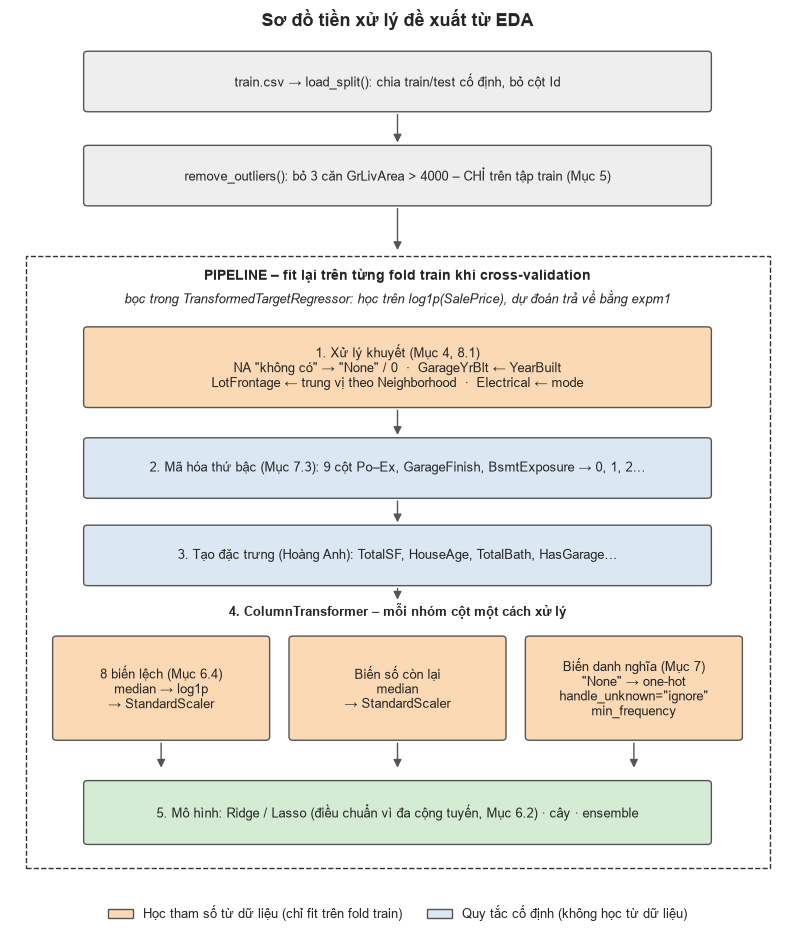

In [36]:
def hop(ax, x, y, w, h, chu, mau):
    """Vẽ một hộp bo góc có chữ ở giữa."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05",
                                fc=mau, ec="#555555"))
    ax.text(x + w / 2, y + h / 2, chu, ha="center", va="center", fontsize=9)


def mui_ten(ax, x, y1, y2):
    """Vẽ mũi tên thẳng đứng từ y1 xuống y2."""
    ax.annotate("", xy=(x, y2), xytext=(x, y1),
                arrowprops=dict(arrowstyle="-|>", color="#555555"))


XAM, CO_DINH, HOC = "#eeeeee", "#dbe7f3", "#fbd9b5"  # cam: học tham số từ fold train

fig, ax = plt.subplots(figsize=(10, 11))
ax.set_xlim(0, 10)
ax.set_ylim(0, 12.6)
ax.axis("off")

# Các hộp rộng, xếp dọc: (y, chiều cao, nội dung, màu)
cac_buoc = [
    (11.5, 0.8, "train.csv → load_split(): chia train/test cố định, bỏ cột Id", XAM),
    (10.1, 0.8, "remove_outliers(): bỏ 3 căn GrLivArea > 4000 – CHỈ trên tập train (Mục 5)", XAM),
    (7.1, 1.1, "1. Xử lý khuyết (Mục 4, 8.1)\n"
               "NA \"không có\" → \"None\" / 0  ·  GarageYrBlt ← YearBuilt\n"
               "LotFrontage ← trung vị theo Neighborhood  ·  Electrical ← mode", HOC),
    (5.75, 0.8, "2. Mã hóa thứ bậc (Mục 7.3): 9 cột Po–Ex, GarageFinish, BsmtExposure → 0, 1, 2…",
     CO_DINH),
    (4.45, 0.8, "3. Tạo đặc trưng (Hoàng Anh): TotalSF, HouseAge, TotalBath, HasGarage…", CO_DINH),
    (0.6, 0.85, "5. Mô hình: Ridge / Lasso (điều chuẩn vì đa cộng tuyến, Mục 6.2) · cây · ensemble",
     "#d5ecd4"),
]
for y, h, chu, mau in cac_buoc:
    hop(ax, 1, y, 8, h, chu, mau)
for y1, y2 in [(11.45, 10.95), (10.05, 9.35), (7.05, 6.6), (5.7, 5.3), (4.4, 4.15)]:
    mui_ten(ax, 5, y1, y2)

# Khung Pipeline: mọi bước bên trong được fit lại trên từng fold
ax.add_patch(plt.Rectangle((0.2, 0.2), 9.6, 9.1, fill=False, ls="--", ec="#333333"))
ax.text(5, 8.95, "PIPELINE – fit lại trên từng fold train khi cross-validation",
        ha="center", fontsize=10, fontweight="bold")
ax.text(5, 8.6, "bọc trong TransformedTargetRegressor: học trên log1p(SalePrice), "
        "dự đoán trả về bằng expm1", ha="center", fontsize=9, style="italic")

# Bước 4: ColumnTransformer chia 3 nhánh song song
ax.text(5, 3.95, "4. ColumnTransformer – mỗi nhóm cột một cách xử lý",
        ha="center", fontsize=9.5, fontweight="bold")
nhanh = [
    "8 biến lệch (Mục 6.4)\nmedian → log1p\n→ StandardScaler",
    "Biến số còn lại\nmedian\n→ StandardScaler",
    "Biến danh nghĩa (Mục 7)\n\"None\" → one-hot\nhandle_unknown=\"ignore\"\nmin_frequency",
]
for i, chu in enumerate(nhanh):
    hop(ax, 0.6 + i * 3.05, 2.15, 2.7, 1.45, chu, HOC)
    mui_ten(ax, 1.95 + i * 3.05, 2.1, 1.65)

chu_giai = [
    Patch(fc=HOC, ec="#555555", label="Học tham số từ dữ liệu (chỉ fit trên fold train)"),
    Patch(fc=CO_DINH, ec="#555555", label="Quy tắc cố định (không học từ dữ liệu)"),
]
ax.legend(handles=chu_giai, loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=2,
          fontsize=9, frameon=False)
ax.set_title("Sơ đồ tiền xử lý đề xuất từ EDA", fontsize=13, fontweight="bold")
save_fig(fig, "eda_13_so_do_pipeline")
plt.show()

### 8.5. Các điểm cần cả nhóm chốt (Buổi 3, 25/11)
1. `GarageYrBlt`: điền `YearBuilt` như bảng trên, hay bỏ hẳn cột vì gần trùng `YearBuilt` (r = 0,82, Mục 6.2)?
2. `BsmtFinType1/2`: one-hot (theo Mục 8.2) hay ordinal? → so sánh bằng CV.
3. `log1p` cho 8 biến lệch: cần thêm nhánh riêng trong `ColumnTransformer`; so CV của Ridge/Lasso/KNN khi có và không có log.
4. Bỏ `Utilities`, `Street`, `PoolQC` hay giữ lại?
5. `MoSold`, `YrSold`: giữ dạng số hay chuyển sang phân loại (cả hai gần như không tương quan với giá, Mục 6.1)?
6. `min_frequency` của one-hot: 0,01 (≈ 9 căn trong mỗi fold train) hay giá trị khác.

**Kết luận notebook 01:**
1. Biến mục tiêu lệch phải → huấn luyện trên `log1p(SalePrice)` (skew 1,74 → 0,13).
2. Phần lớn giá trị khuyết là thông tin "không có" → điền `"None"`/0, không xóa dòng hay cột; chỉ 4 cột khuyết thật.
3. Loại 3 căn `GrLivArea > 4000` trên train; các giá trị lớn khác là thật, xử lý bằng `log1p` thay vì xóa.
4. Giá phụ thuộc mạnh nhất vào chất lượng (`OverallQual`), diện tích và khu phố (`Neighborhood`);
   đa cộng tuyến và ~264 cột sau one-hot → ưu tiên mô hình có điều chuẩn.
5. Mọi bước học từ dữ liệu nằm trong Pipeline (sơ đồ Mục 8.4) → không rò rỉ dữ liệu khi cross-validation.